# 📊 Statistics for Data Science — Practicals

**This notebook follows `Statistics_Beginner_Slides.html` slide by slide.**
Every section is tagged with the slide it belongs to, so theory and code stay in sync.
Nothing extra is introduced — only the concepts that appear in the deck.

**Dataset:** `data/indian_engineering_student_placement.csv` (the same one used in the slides and notes)

| Part | Topic |
|---|---|
| 0 | The dataset · Population vs Sample · Types of Data |
| 1 | Measures of Central Tendency |
| 2 | Dispersion: Variance & Standard Deviation |
| 3 | Distributions |
| 4 | Just Enough Probability |
| 5 | Standard Normal & Z-Scores |
| 6 | Sampling Techniques |
| 7 | Hypothesis Testing & the Z-Test |

> 🎞️ = the slide this cell puts into practice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)
np.random.seed(42)
 
BLUE, RED, GREEN, ORANGE = "#0B3676", "#d1495b", "#2e9e5b", "#e8952f"
print("ready")

ready


---
# Part 0 — The dataset, Population vs Sample, Types of Data

### 🎞️ Slide: *Our dataset at a glance*

In [ ]:
csv_path = r"D:\Data Science_bat\Statistics\data\indian_engineering_student_placement.csv"
df = pd.read_csv(csv_path)
df.head()

,Student_ID,gender,branch,cgpa,tenth_percentage,twelfth_percentage,backlogs,study_hours_per_day,attendance_percentage,projects_completed,...,aptitude_skill_rating,hackathons_participated,certifications_count,sleep_hours,stress_level,part_time_job,family_income_level,city_tier,internet_access,extracurricular_involvement
0,1,Male,ECE,8.74,74.0,75.0,0,3.8,71.1,7,...,5,4,5,6.5,8,Yes,Medium,Tier 2,Yes,Medium
1,2,Female,ECE,7.80,75.3,69.7,0,6.3,69.5,5,...,3,4,1,7.1,8,Yes,Medium,Tier 3,Yes,Low
2,3,Female,IT,6.95,62.8,68.3,0,1.5,62.5,8,...,4,6,3,6.1,2,No,Low,Tier 2,Yes,High
3,4,Male,ECE,7.46,57.9,51.4,1,4.7,64.6,6,...,4,2,2,7.3,7,No,Medium,Tier 1,Yes,Low
4,5,Male,IT,6.86,61.3,73.5,2,5.2,75.9,3,...,3,2,1,6.0,7,No,Medium,Tier 1,Yes,Medium


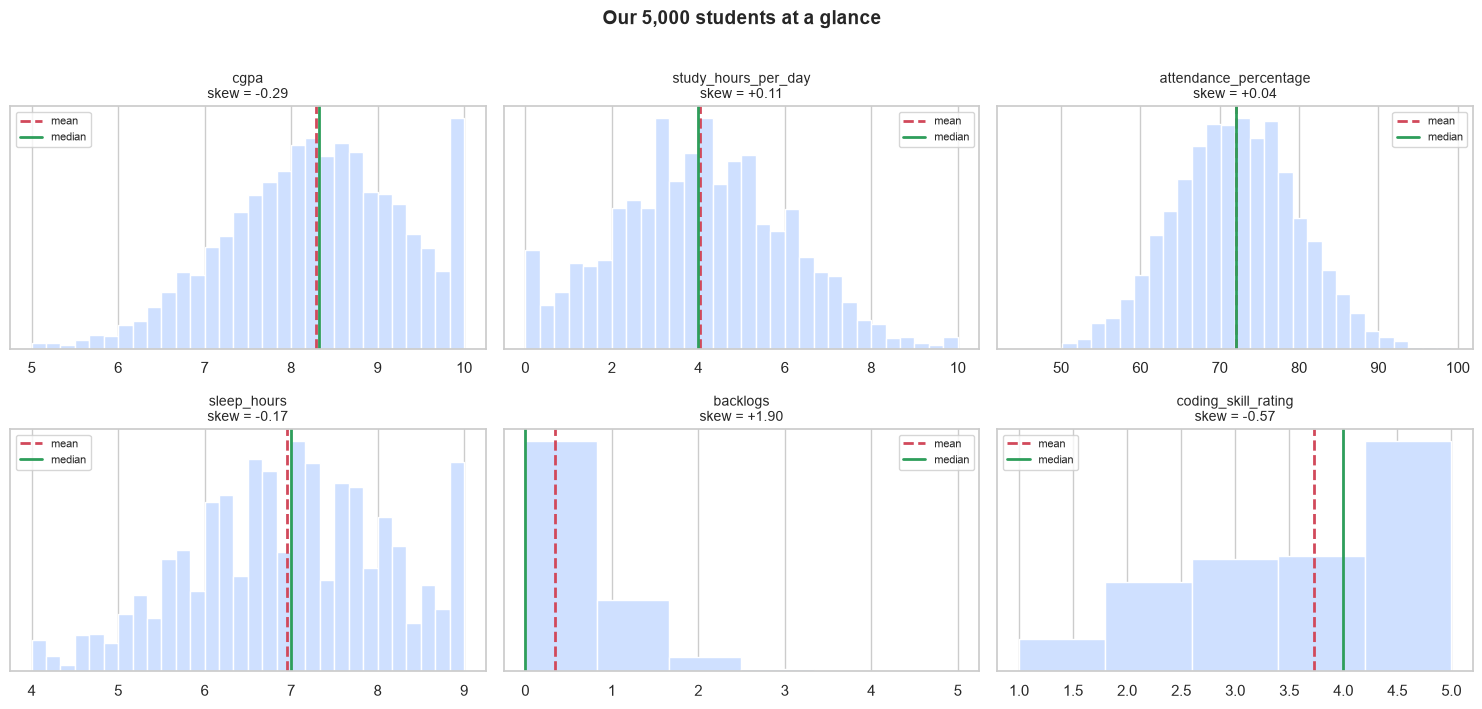

In [50]:
# The exact chart from the slide: 6 columns, red = mean, green = median
overview = ["cgpa", "study_hours_per_day", "attendance_percentage",
            "sleep_hours", "backlogs", "coding_skill_rating"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), overview):
    ax.hist(df[c], bins=min(30, df[c].nunique()), color="#cfe0ff", edgecolor="white")
    ax.axvline(df[c].mean(), color=RED, ls="--", lw=2, label="mean")
    ax.axvline(df[c].median(), color=GREEN, lw=2, label="median")
    ax.set_title(f"{c}\nskew = {df[c].skew():+.2f}", fontsize=10)
    ax.set_yticks([]); ax.legend(fontsize=8)
fig.suptitle("Our 5,000 students at a glance", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

### 🎞️ Slides: *Population vs Sample* / *Population vs Sample — the picture*

| | Population | Sample |
|---|---|---|
| Size | $N$ | $n$ |
| Mean | $\mu$ (parameter) | $\bar{x}$ (statistic) |
| Std dev | $\sigma$ | $s$ |

We treat the **whole CSV as the population** so we can check how well a sample estimates it.

In [51]:
population = df.copy()
COL = "cgpa"

MU    = population[COL].mean()
SIGMA = population[COL].std(ddof=0)      # ddof=0 -> population sigma

sample = population.sample(n=200, random_state=42)
xbar   = sample[COL].mean()
s      = sample[COL].std(ddof=1)         # ddof=1 -> sample s

print(f"POPULATION  N = {len(population):>5,}   mu    = {MU:.4f}   sigma = {SIGMA:.4f}")
print(f"SAMPLE      n = {len(sample):>5,}   x-bar = {xbar:.4f}   s     = {s:.4f}")
print(f"\nestimation error = {xbar - MU:+.4f} CGPA")

POPULATION  N = 5,000   mu    = 8.2838   sigma = 1.0083
SAMPLE      n =   200   x-bar = 8.3119   s     = 1.0821

estimation error = +0.0282 CGPA


### 🎞️ Slide: *Types of Data*

```
Numerical  -> Discrete (countable) / Continuous (measurable)
Categorical-> Nominal (no order)   / Ordinal (has order)
```
**The data type decides the statistic.**

In [52]:
num_df = df.select_dtypes(include=["number"])
cat_df = df.select_dtypes(include=["object"])

types = pd.DataFrame([
    ("cgpa",                  "Numerical",   "Continuous"),
    ("attendance_percentage", "Numerical",   "Continuous"),
    ("backlogs",              "Numerical",   "Discrete"),
    ("projects_completed",    "Numerical",   "Discrete"),
    ("gender",                "Categorical", "Nominal"),
    ("branch",                "Categorical", "Nominal"),
    ("family_income_level",   "Categorical", "Ordinal"),
    ("city_tier",             "Categorical", "Ordinal"),
], columns=["column", "type", "sub-type"])
display(types)

print("mean of cgpa   =", round(df["cgpa"].mean(), 3), " <- makes sense")
print("mode of branch =", df["branch"].mode()[0], "        <- the only sensible summary for a category")

,column,type,sub-type
0,cgpa,Numerical,Continuous
1,attendance_percentage,Numerical,Continuous
2,backlogs,Numerical,Discrete
3,projects_completed,Numerical,Discrete
4,gender,Categorical,Nominal
5,branch,Categorical,Nominal
6,family_income_level,Categorical,Ordinal
7,city_tier,Categorical,Ordinal


mean of cgpa   = 8.284  <- makes sense
mode of branch = CSE         <- the only sensible summary for a category


---
# Part 1 — Measures of Central Tendency

### 🎞️ Slide: *One number to describe them all*

$$\bar{x}=\frac{\sum x_i}{n} \qquad \text{median} = \text{middle value} \qquad \text{mode} = \text{most frequent}$$

In [53]:
print(f"mean   = {df[COL].mean():.4f}")
print(f"median = {df[COL].median():.4f}")
print(f"mode   = {df[COL].mode()[0]:.4f}")

# the same three, computed by hand
x = np.sort(df[COL].dropna().to_numpy())
n = len(x)
manual_mean   = x.sum() / n
manual_median = x[n // 2] if n % 2 else (x[n // 2 - 1] + x[n // 2]) / 2
print(f"\nby hand -> mean {manual_mean:.4f}  median {manual_median:.4f}")

mean   = 8.2838
median = 8.3200
mode   = 10.0000

by hand -> mean 8.2838  median 8.3200


branch          mode = CSE
gender          mode = Male
stress_level    mode = 10


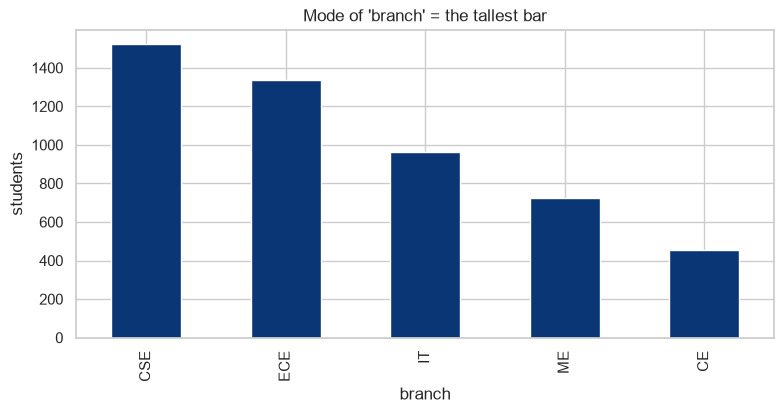

In [54]:
# Mode is the ONLY option for categorical columns
for c in ["branch", "gender", "stress_level"]:
    print(f"{c:15s} mode = {df[c].mode()[0]}")

df["branch"].value_counts().plot(kind="bar", color=BLUE, title="Mode of 'branch' = the tallest bar")
plt.ylabel("students"); plt.show()

### 🎞️ Slide: *Symmetric vs Skewed — see it*

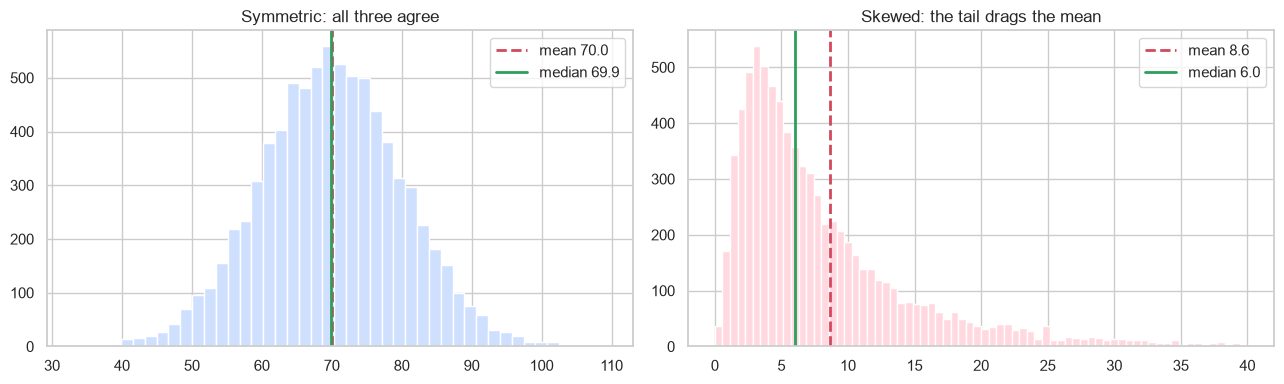

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

sym = np.random.normal(70, 10, 8000)                      # exam marks
ax[0].hist(sym, bins=45, color="#cfe0ff", edgecolor="white")
ax[0].axvline(sym.mean(), color=RED, ls="--", lw=2, label=f"mean {sym.mean():.1f}")
ax[0].axvline(np.median(sym), color=GREEN, lw=2, label=f"median {np.median(sym):.1f}")
ax[0].set_title("Symmetric: all three agree"); ax[0].legend()

salary = np.random.lognormal(np.log(6), 0.85, 8000)       # salary in LPA
ax[1].hist(salary, bins=70, range=(0, 40), color="#ffd9df", edgecolor="white")
ax[1].axvline(salary.mean(), color=RED, ls="--", lw=2, label=f"mean {salary.mean():.1f}")
ax[1].axvline(np.median(salary), color=GREEN, lw=2, label=f"median {np.median(salary):.1f}")
ax[1].set_title("Skewed: the tail drags the mean"); ax[1].legend()
plt.tight_layout(); plt.show()

### 🎞️ Slide: *The Outlier Demo 💥*

In [56]:
salaries = np.array([30, 35, 40, 45, 50])          # thousands / month
with_ceo = np.append(salaries, 10_000)             # one CEO joins

display(pd.DataFrame({
    "Mean":   [salaries.mean(), with_ceo.mean()],
    "Median": [np.median(salaries), np.median(with_ceo)],
}, index=["Without CEO", "With CEO"]).round(1))

print("The mean claims an 'average salary' of", f"{with_ceo.mean():,.0f}k/month - a lie.")
print("The median barely moves. For skewed data, report the MEDIAN.")

,Mean,Median
Without CEO,40.0,40.0
With CEO,1700.0,42.5


The mean claims an 'average salary' of 1,700k/month - a lie.
The median barely moves. For skewed data, report the MEDIAN.


**Rule from the slide:** symmetric → mean · skewed/outliers → median · categorical → mode

---
# Part 2 — Dispersion: Variance & Standard Deviation

### 🎞️ Slide: *Why the mean alone is dangerous*

Class A: mean = 7.00   std = 0.00
Class B: mean = 7.00   std = 3.00


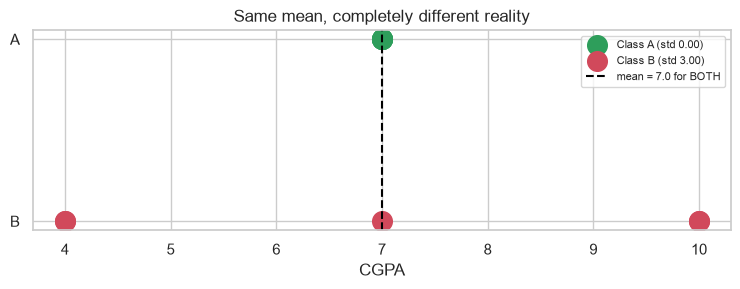

In [57]:
class_A = np.array([7.0, 7.0, 7.0, 7.0, 7.0])
class_B = np.array([4.0, 4.0, 7.0, 10.0, 10.0])

for name, arr in [("Class A", class_A), ("Class B", class_B)]:
    print(f"{name}: mean = {arr.mean():.2f}   std = {arr.std(ddof=1):.2f}")

plt.figure(figsize=(9, 2.6))
plt.scatter(class_A, [2]*5, s=200, color=GREEN, label="Class A (std 0.00)")
plt.scatter(class_B, [1]*5, s=200, color=RED,   label="Class B (std 3.00)")
plt.axvline(7.0, color="black", ls="--", label="mean = 7.0 for BOTH")
plt.yticks([1, 2], ["B", "A"]); plt.xlabel("CGPA"); plt.legend(fontsize=8)
plt.title("Same mean, completely different reality"); plt.show()

### 🎞️ Slides: *Variance* / *Standard Deviation* / *Work it out by hand (once!)*

$$\sigma^2=\frac{\sum (x_i-\mu)^2}{N} \qquad s^2=\frac{\sum (x_i-\bar{x})^2}{n-1} \qquad s=\sqrt{s^2}$$

In [58]:
d = np.array([2, 4, 4, 4, 5, 5, 7, 9])       # the exact data from the slide
mean_d = d.mean()
dev    = d - mean_d
sq     = dev ** 2

display(pd.DataFrame({"x": d, "x - mean": dev, "(x - mean)²": sq}))

print(f"mean                   = {mean_d}")
print(f"sum of deviations      = {dev.sum():.1f}   <-- ALWAYS 0, that is why we square")
print(f"sum of squared devs    = {sq.sum()}")
print(f"population  /N         = {sq.sum()/len(d):.4f}   -> sigma = {np.sqrt(sq.sum()/len(d)):.4f}")
print(f"sample      /(n-1)     = {sq.sum()/(len(d)-1):.4f}   -> s     = {np.sqrt(sq.sum()/(len(d)-1)):.4f}")

,x,x - mean,(x - mean)²
0,2,-3.0,9.0
1,4,-1.0,1.0
2,4,-1.0,1.0
3,4,-1.0,1.0
4,5,0.0,0.0
5,5,0.0,0.0
6,7,2.0,4.0
7,9,4.0,16.0


mean                   = 5.0
sum of deviations      = 0.0   <-- ALWAYS 0, that is why we square
sum of squared devs    = 32.0
population  /N         = 4.0000   -> sigma = 2.0000
sample      /(n-1)     = 4.5714   -> s     = 2.1381


In [59]:
# ⚠️ The ddof trap from the slide
print("numpy  var, ddof=0 (population):", np.var(d))
print("numpy  var, ddof=1 (sample)    :", np.var(d, ddof=1))
print("pandas var (default is ddof=1) :", pd.Series(d).var())
print("\npandas defaults to n-1, numpy defaults to n.")

numpy  var, ddof=0 (population): 4.0
numpy  var, ddof=1 (sample)    : 4.571428571428571
pandas var (default is ddof=1) : 4.571428571428571

pandas defaults to n-1, numpy defaults to n.


In [60]:
# Standard deviation puts us back in the original unit
spread = pd.DataFrame({
    "min": num_df.min(), "max": num_df.max(),
    "range": num_df.max() - num_df.min(),
    "variance": num_df.var(), "std_dev": num_df.std(),
}).round(3)
spread.loc[overview]

,min,max,range,variance,std_dev
cgpa,5.0,10.0,5.0,1.017,1.008
study_hours_per_day,0.0,10.0,10.0,3.872,1.968
attendance_percentage,44.7,99.2,54.5,59.599,7.720
sleep_hours,4.0,9.0,5.0,1.318,1.148
backlogs,0.0,5.0,5.0,0.375,0.613
coding_skill_rating,1.0,5.0,4.0,1.634,1.278


### 🎞️ Slide: *IQR & the boxplot outlier rule*

$IQR = Q_3 - Q_1$ · outlier if $x < Q_1 - 1.5\,IQR$ or $x > Q_3 + 1.5\,IQR$

Q1 = 7.610   median = 8.320   Q3 = 9.020   IQR = 1.410
fences = [5.495, 11.135]  ->  23 outliers


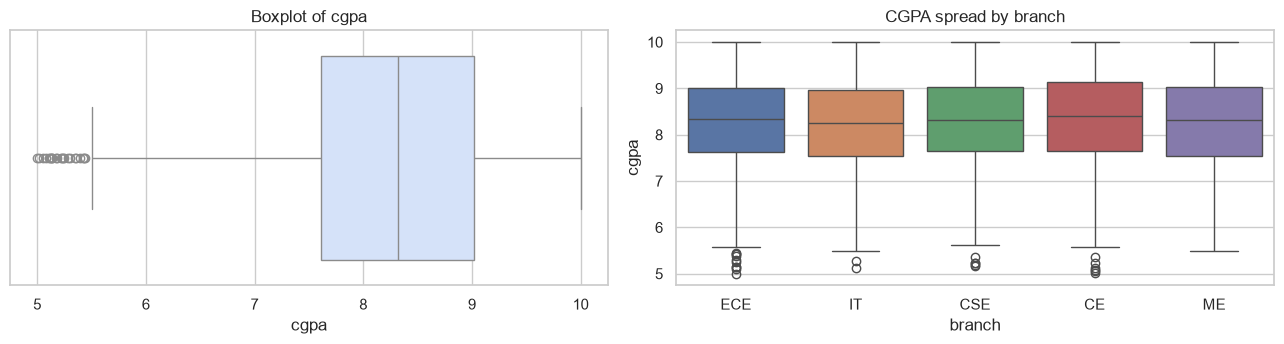

In [61]:
s_col = df[COL].dropna()
q1, med, q3 = s_col.quantile([0.25, 0.50, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = s_col[(s_col < lo) | (s_col > hi)]

print(f"Q1 = {q1:.3f}   median = {med:.3f}   Q3 = {q3:.3f}   IQR = {iqr:.3f}")
print(f"fences = [{lo:.3f}, {hi:.3f}]  ->  {len(outliers)} outliers")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
sns.boxplot(x=s_col, ax=ax[0], color="#cfe0ff"); ax[0].set_title(f"Boxplot of {COL}")
sns.boxplot(data=df, x="branch", y=COL, ax=ax[1], hue="branch", legend=False)
ax[1].set_title("CGPA spread by branch")
plt.tight_layout(); plt.show()

### 🎞️ Slide: *Boxplot ↔ the bell curve*
For a normal population the box covers ≈ ±0.67σ (the middle 50%) and the whiskers reach ≈ ±2.7σ.

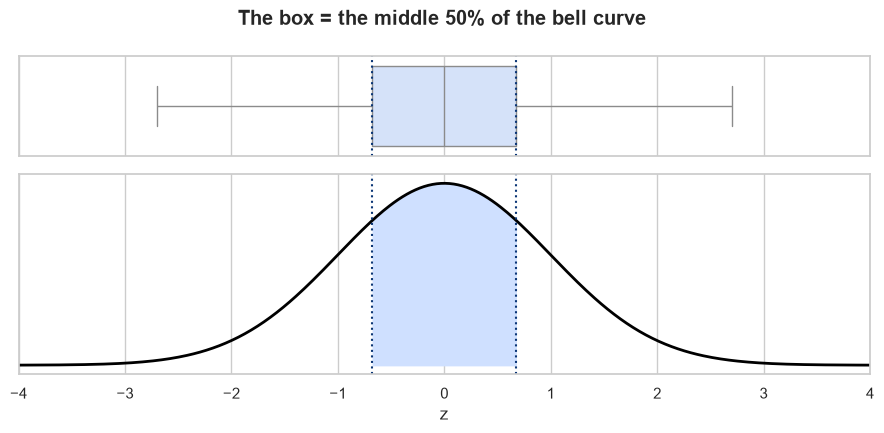

Q1 = -0.675 sigma, Q3 = +0.675 sigma
whisker reach = 2.70 sigma


In [62]:
z = np.random.normal(0, 1, 200_000)
fig, ax = plt.subplots(2, 1, figsize=(9, 4.4), sharex=True,
                       gridspec_kw={"height_ratios": [1, 2]})
sns.boxplot(x=z, ax=ax[0], color="#cfe0ff", fliersize=0); ax[0].set_xlim(-4, 4)
xs = np.linspace(-4, 4, 400)
ax[1].plot(xs, stats.norm.pdf(xs), color="black", lw=2)
for v in (np.percentile(z, 25), np.percentile(z, 75)):
    ax[0].axvline(v, color=BLUE, ls=":"); ax[1].axvline(v, color=BLUE, ls=":")
ax[1].fill_between(xs, stats.norm.pdf(xs),
                   where=(xs > np.percentile(z, 25)) & (xs < np.percentile(z, 75)),
                   color="#cfe0ff")
ax[1].set_yticks([]); ax[1].set_xlabel("z")
fig.suptitle("The box = the middle 50% of the bell curve", fontweight="bold")
plt.tight_layout(); plt.show()

print(f"Q1 = {np.percentile(z,25):+.3f} sigma, Q3 = {np.percentile(z,75):+.3f} sigma")
print(f"whisker reach = {1.5*stats.iqr(z) + np.percentile(z,75):.2f} sigma")

---
# Part 3 — Distributions

### 🎞️ Slides: *Shape vocabulary* / *Negative vs positive skew*

| Shape | Relationship |
|---|---|
| Symmetric | mean ≈ median ≈ mode |
| Right (positive) skew | mean > median > mode |
| Left (negative) skew | mean < median < mode |

**The tail pulls the mean.**

In [63]:
shape = pd.DataFrame({"mean": num_df.mean(), "median": num_df.median(),
                      "skewness": num_df.skew()})
shape["verdict"] = pd.cut(shape["skewness"], [-np.inf, -0.5, 0.5, np.inf],
                          labels=["left skewed", "fairly symmetric", "right skewed"])
shape.round(3).sort_values("skewness")

,mean,median,skewness,verdict
coding_skill_rating,3.729,4.00,-0.565,left skewed
projects_completed,5.529,6.00,-0.533,left skewed
hackathons_participated,3.704,4.00,-0.374,fairly symmetric
aptitude_skill_rating,4.116,4.00,-0.368,fairly symmetric
cgpa,8.284,8.32,-0.288,fairly symmetric
sleep_hours,6.955,7.00,-0.172,fairly symmetric
tenth_percentage,74.537,74.70,-0.135,fairly symmetric
stress_level,6.020,6.00,-0.134,fairly symmetric
twelfth_percentage,74.543,74.80,-0.091,fairly symmetric
internships_completed,2.133,2.00,-0.088,fairly symmetric


### 🎞️ Slide: *Distributions to recognise*

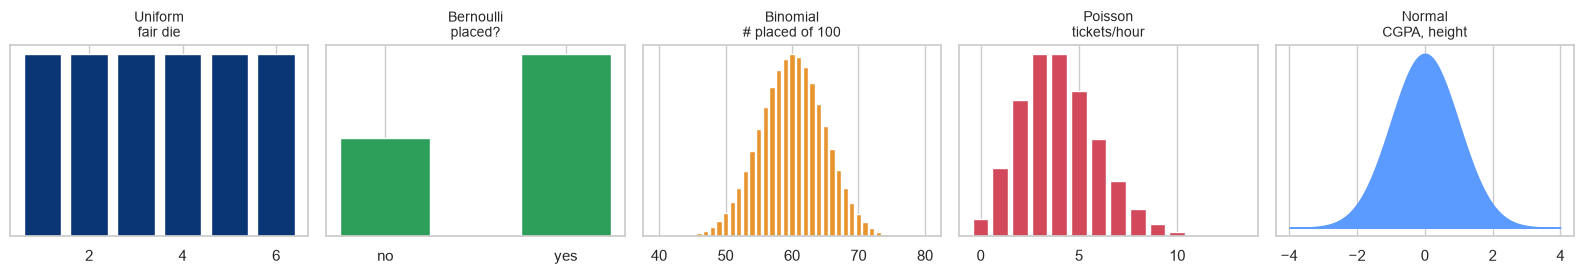

In [64]:
fig, ax = plt.subplots(1, 5, figsize=(16, 2.9))

ax[0].bar(range(1, 7), [1/6]*6, color=BLUE)
ax[0].set_title("Uniform\nfair die", fontsize=10)

ax[1].bar([0, 1], [0.35, 0.65], color=GREEN, width=.5)
ax[1].set_xticks([0, 1], ["no", "yes"]); ax[1].set_title("Bernoulli\nplaced?", fontsize=10)

k = np.arange(40, 81)
ax[2].bar(k, stats.binom.pmf(k, 100, 0.6), color=ORANGE)
ax[2].set_title("Binomial\n# placed of 100", fontsize=10)

k2 = np.arange(0, 14)
ax[3].bar(k2, stats.poisson.pmf(k2, 4), color=RED)
ax[3].set_title("Poisson\ntickets/hour", fontsize=10)

xs = np.linspace(-4, 4, 400)
ax[4].fill_between(xs, stats.norm.pdf(xs), color="#5b9bff")
ax[4].set_title("Normal\nCGPA, height", fontsize=10)

for a in ax: a.set_yticks([])
plt.tight_layout(); plt.show()

### 🎞️ Slides: *The Normal Distribution* / *μ moves it, σ stretches it*

$$f(x)=\frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{(x-\mu)^2}{2\sigma^2}}$$

our formula : 0.24197072451914337
scipy       : 0.24197072451914337


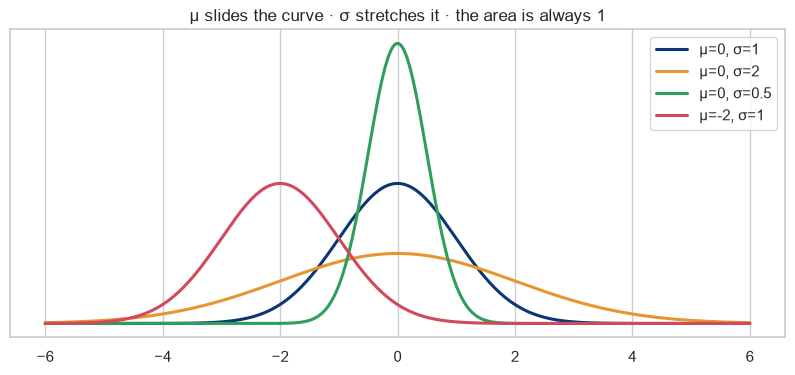

In [65]:
def normal_pdf(x, mu, sigma):
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2))

print("our formula :", normal_pdf(1.0, 0, 1))
print("scipy       :", stats.norm.pdf(1.0, 0, 1))

xs = np.linspace(-6, 6, 600)
plt.figure(figsize=(10, 4))
for mu, sd, c in [(0, 1, BLUE), (0, 2, ORANGE), (0, 0.5, GREEN), (-2, 1, RED)]:
    plt.plot(xs, normal_pdf(xs, mu, sd), lw=2.2, color=c, label=f"μ={mu}, σ={sd}")
plt.title("μ slides the curve · σ stretches it · the area is always 1")
plt.legend(); plt.yticks([]); plt.show()

### 🎞️ Slides: *The Empirical Rule: 68 – 95 – 99.7* / *The reference version*

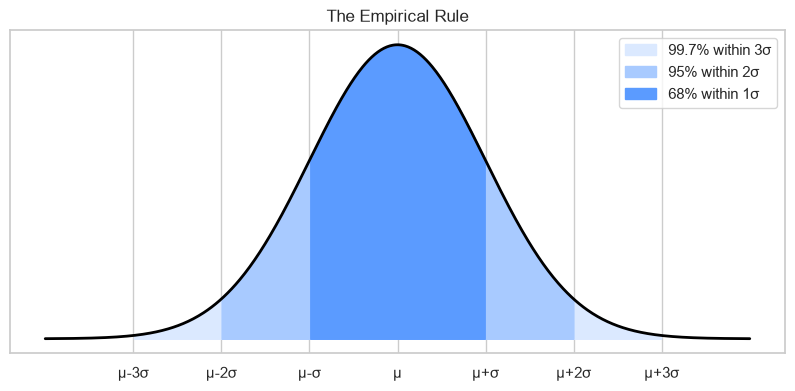

theory:  68.27% within 1 sigma
theory:  95.45% within 2 sigma
theory:  99.73% within 3 sigma


In [66]:
xs = np.linspace(-4, 4, 700)
pdf = stats.norm.pdf(xs)

plt.figure(figsize=(10, 4.2))
plt.plot(xs, pdf, color="black", lw=2)
for k, c, lbl in [(3, "#dbe9ff", "99.7% within 3σ"),
                  (2, "#a8caff", "95% within 2σ"),
                  (1, "#5b9bff", "68% within 1σ")]:
    m = (xs >= -k) & (xs <= k)
    plt.fill_between(xs[m], pdf[m], color=c, label=lbl)
plt.xticks(range(-3, 4), ["μ-3σ", "μ-2σ", "μ-σ", "μ", "μ+σ", "μ+2σ", "μ+3σ"])
plt.yticks([]); plt.legend(); plt.title("The Empirical Rule"); plt.show()

for k in (1, 2, 3):
    print(f"theory: {100*(stats.norm.cdf(k)-stats.norm.cdf(-k)):6.2f}% within {k} sigma")

In [67]:
# Does our real CGPA obey the rule?
m_, s_ = df[COL].mean(), df[COL].std()
for k, expected in zip((1, 2, 3), (68.27, 95.45, 99.73)):
    actual = df[COL].between(m_ - k*s_, m_ + k*s_).mean() * 100
    print(f"within {k} sigma -> actual {actual:5.2f}%   (theory {expected}%)")

print(f"\n3-sigma range for CGPA: [{m_-3*s_:.2f}, {m_+3*s_:.2f}]")
print(f"students beyond 3 sigma: {(np.abs(stats.zscore(df[COL])) > 3).sum()}")

within 1 sigma -> actual 65.84%   (theory 68.27%)
within 2 sigma -> actual 97.24%   (theory 95.45%)
within 3 sigma -> actual 99.70%   (theory 99.73%)

3-sigma range for CGPA: [5.26, 11.31]
students beyond 3 sigma: 15


---
# Part 4 — Just Enough Probability

### 🎞️ Slides: *Probability basics* / *The same rules, as pictures*

$$P(A)=\frac{\text{favourable}}{\text{total}} \qquad P(A')=1-P(A) \qquad P(A\cup B)=P(A)+P(B)-P(A\cap B)$$
$$P(A\cap B)=P(A)P(B)\ \text{(if independent)} \qquad P(A\mid B)=\frac{P(A\cap B)}{P(B)} \qquad P(A\mid B)=\frac{P(B\mid A)P(A)}{P(B)}$$

In [68]:
A = df["branch"] == "CSE"       # event A: student is in CSE
B = df["cgpa"] > 8              # event B: CGPA above 8

pA, pB, pAB = A.mean(), B.mean(), (A & B).mean()

print(f"P(A)  = P(CSE)      = {pA:.4f}")
print(f"P(B)  = P(CGPA>8)   = {pB:.4f}")
print(f"P(A')               = {1 - pA:.4f}          (complement)")
print(f"P(A ∩ B)            = {pAB:.4f}")
print(f"P(A ∪ B)            = {pA + pB - pAB:.4f}          (addition rule)")
print(f"P(B | A)            = {pAB / pA:.4f}          (conditional)")
print(f"P(A) × P(B)         = {pA * pB:.4f}          (what it would be IF independent)")
print(f"\nP(A|B) via Bayes    = {(pAB/pB * pB) / pB:.4f}  =  P(B|A)P(A)/P(B) = {(pAB/pA)*pA/pB:.4f}")

P(A)  = P(CSE)      = 0.3044
P(B)  = P(CGPA>8)   = 0.6202
P(A')               = 0.6956          (complement)
P(A ∩ B)            = 0.1918
P(A ∪ B)            = 0.7328          (addition rule)
P(B | A)            = 0.6301          (conditional)
P(A) × P(B)         = 0.1888          (what it would be IF independent)

P(A|B) via Bayes    = 0.3093  =  P(B|A)P(A)/P(B) = 0.3093


### 🎞️ Slide: *Continuous probability = AREA*

| You want | Python |
|---|---|
| $P(Z\le z)$ | `norm.cdf(z)` |
| $P(Z>z)$ | `1 - norm.cdf(z)` |
| $P(a<Z<b)$ | `norm.cdf(b) - norm.cdf(a)` |

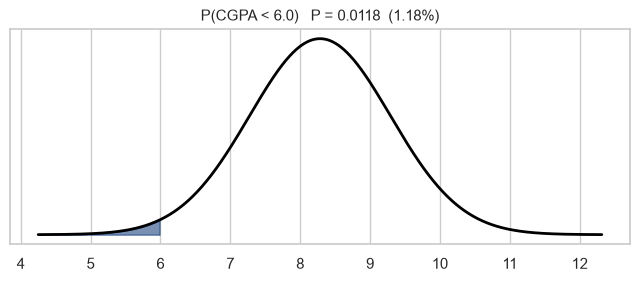

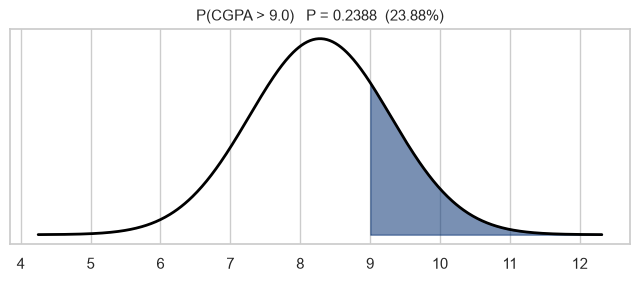

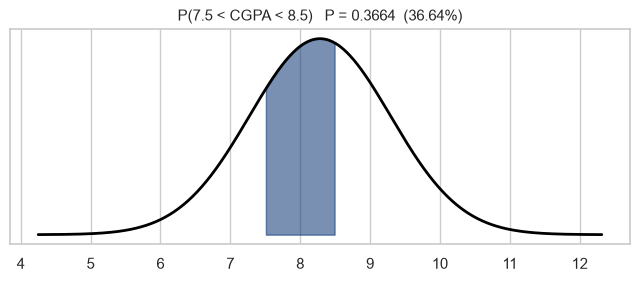

P(CGPA exactly 8.000) = 0   <- a single point has zero width


In [69]:
def shade(mu, sigma, a=None, b=None, title=""):
    xs = np.linspace(mu - 4*sigma, mu + 4*sigma, 600)
    ys = stats.norm.pdf(xs, mu, sigma)
    lo_, hi_ = (a if a is not None else -np.inf), (b if b is not None else np.inf)
    p = stats.norm.cdf(hi_, mu, sigma) - stats.norm.cdf(lo_, mu, sigma)

    plt.figure(figsize=(8, 2.8))
    plt.plot(xs, ys, color="black", lw=2)
    m = (xs >= lo_) & (xs <= hi_)
    plt.fill_between(xs[m], ys[m], color=BLUE, alpha=.55)
    plt.title(f"{title}   P = {p:.4f}  ({p*100:.2f}%)", fontsize=11)
    plt.yticks([]); plt.show()
    return p

shade(m_, s_, b=6.0,        title="P(CGPA < 6.0)")
shade(m_, s_, a=9.0,        title="P(CGPA > 9.0)")
shade(m_, s_, a=7.5, b=8.5, title="P(7.5 < CGPA < 8.5)")

print("P(CGPA exactly 8.000) =", 0, "  <- a single point has zero width")

---
# Part 5 — Standard Normal & Z-Scores

### 🎞️ Slides: *Standardization* / *Three students on one curve*

$$z=\frac{x-\mu}{\sigma} \qquad Z\sim N(0,1)$$

In [70]:
df["cgpa_z"] = stats.zscore(df[COL])
print(f"mean of z = {df['cgpa_z'].mean():.6f}   (≈ 0)")
print(f"std  of z = {df['cgpa_z'].std(ddof=0):.6f}   (≈ 1)")

df[["Student_ID", "branch", COL, "cgpa_z"]].sort_values("cgpa_z", ascending=False).head()

mean of z = 0.000000   (≈ 0)
std  of z = 1.000000   (≈ 1)


,Student_ID,branch,cgpa,cgpa_z
4995,4996,IT,10.0,1.702092
4970,4971,CSE,10.0,1.702092
4990,4991,ECE,10.0,1.702092
3947,3948,IT,10.0,1.702092
800,801,CSE,10.0,1.702092


In [71]:
# Exam marks ~ N(70, 10), exactly the slide example
mu_e, sd_e = 70, 10

def explain(marks):
    z = (marks - mu_e) / sd_e
    pct = stats.norm.cdf(z) * 100
    print(f"marks {marks:>3} -> z = {z:+.1f}  ->  {pct:5.1f}th percentile  "
          f"(better than {pct:.0f}% of students)")

for marks in (55, 70, 90):
    explain(marks)

marks  55 -> z = -1.5  ->    6.7th percentile  (better than 7% of students)
marks  70 -> z = +0.0  ->   50.0th percentile  (better than 50% of students)
marks  90 -> z = +2.0  ->   97.7th percentile  (better than 98% of students)


### 🎞️ Slide: *Why standardize? 3 reasons*
1. Compare apples to oranges 2. One table works for every normal 3. ML algorithms need it (`StandardScaler`)

,feature,raw,z,percentile
0,cgpa,8.74,0.452,67.5
1,attendance_percentage,71.10,-0.122,45.1
2,coding_skill_rating,4.00,0.212,58.4
3,study_hours_per_day,3.80,-0.123,45.1


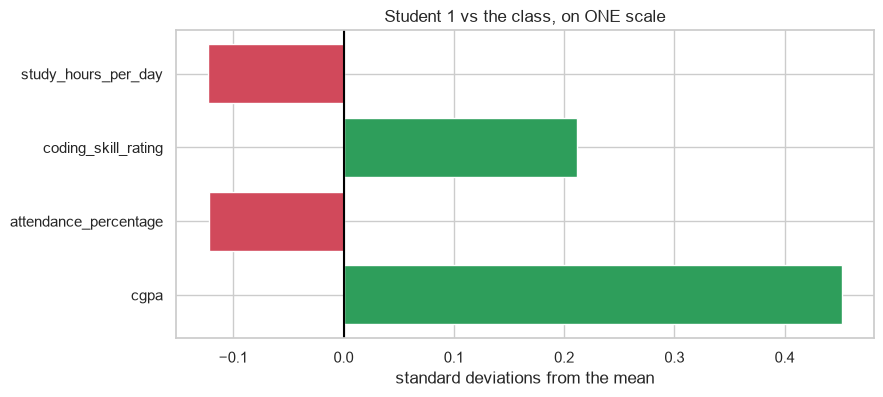

In [72]:
# Reason 1 - is this student's CGPA better than their attendance?
student = df.iloc[0]
rows = []
for c in ["cgpa", "attendance_percentage", "coding_skill_rating", "study_hours_per_day"]:
    z = (student[c] - df[c].mean()) / df[c].std()
    rows.append({"feature": c, "raw": student[c], "z": round(z, 3),
                 "percentile": round(stats.norm.cdf(z) * 100, 1)})
profile = pd.DataFrame(rows)
display(profile)

plt.barh(profile["feature"], profile["z"],
         color=[GREEN if v > 0 else RED for v in profile["z"]])
plt.axvline(0, color="black")
plt.title(f"Student {student['Student_ID']} vs the class, on ONE scale")
plt.xlabel("standard deviations from the mean"); plt.show()

In [73]:
# Reason 3 - StandardScaler is literally (x - mean) / std
from sklearn.preprocessing import StandardScaler

cols = ["cgpa", "attendance_percentage", "study_hours_per_day"]
scaled = StandardScaler().fit_transform(df[cols])

print("sklearn :", np.round(scaled[0], 4))
print("by hand :", np.round(((df[cols].iloc[0] - df[cols].mean()) / df[cols].std(ddof=0)).values, 4))

sklearn : [ 0.4525 -0.122  -0.1225]
by hand : [ 0.4525 -0.122  -0.1225]


---
# Part 6 — Sampling Techniques

### 🎞️ Slides: *Probability sampling* / *The four techniques, side by side*

| Technique | How |
|---|---|
| Simple random | pure lottery |
| Stratified | sample each group proportionally |
| Systematic | every k-th record |
| Cluster | pick whole groups |

In [74]:
# 1) Simple random
srs = population.sample(n=250, random_state=42)

# 2) Stratified - keeps each branch's share intact
strat = population.groupby("branch", group_keys=False).sample(frac=0.05, random_state=42)

# 3) Systematic - every k-th record
k = len(population) // 250
syst = population.iloc[np.random.randint(0, k)::k]

# 4) Cluster - two whole branches
chosen = np.random.choice(population["branch"].unique(), 2, replace=False)
clust = population[population["branch"].isin(chosen)]

summary = pd.DataFrame([
    {"technique": "Simple random", "n": len(srs),   "mean": srs[COL].mean()},
    {"technique": "Stratified",    "n": len(strat), "mean": strat[COL].mean()},
    {"technique": "Systematic",    "n": len(syst),  "mean": syst[COL].mean()},
    {"technique": f"Cluster {list(chosen)}", "n": len(clust), "mean": clust[COL].mean()},
])
summary["error vs mu"] = summary["mean"] - MU
display(summary.round(4))
print(f"true population mu = {MU:.4f}")

,technique,n,mean,error vs mu
0,Simple random,250,8.3318,0.0480
1,Stratified,250,8.2319,-0.0519
2,Systematic,250,8.2512,-0.0326
3,"Cluster ['CE', 'CSE']",1976,8.3064,0.0226


true population mu = 8.2838


In [75]:
# Why stratified matters: it preserves the group proportions
pd.DataFrame({
    "population %":  population["branch"].value_counts(normalize=True) * 100,
    "stratified %":  strat["branch"].value_counts(normalize=True) * 100,
    "simple random %": srs["branch"].value_counts(normalize=True) * 100,
}).round(2)

,population %,stratified %,simple random %
branch,,,
CE,9.08,9.2,7.6
CSE,30.44,30.4,29.2
ECE,26.72,26.8,33.6
IT,19.26,19.2,16.8
ME,14.50,14.4,12.8


### 🎞️ Slides: *Central Limit Theorem 👑* / *CLT in one diagram*

$$\bar{X} \sim N\!\left(\mu,\ \frac{\sigma^2}{n}\right)$$

…**whatever the shape of the population**, for $n \ge 30$.

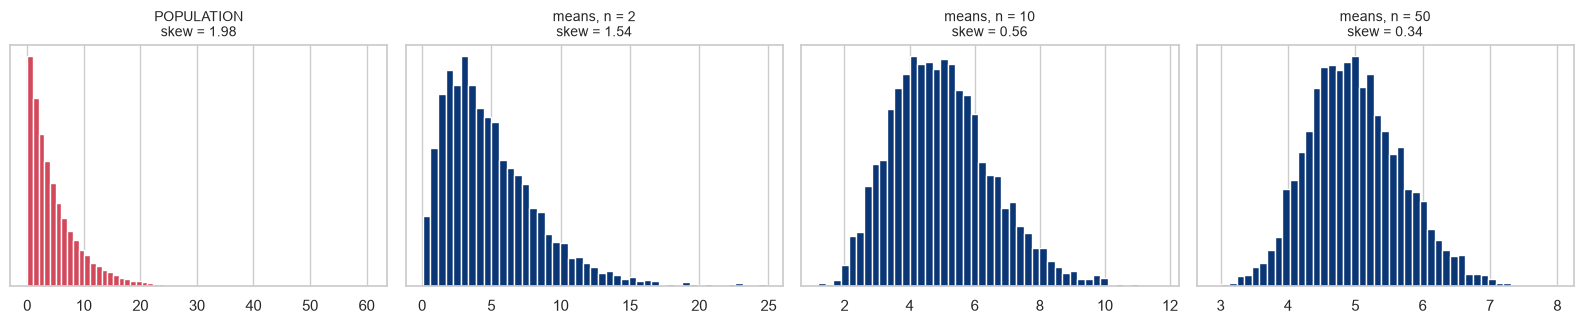

In [76]:
skewed_pop = np.random.exponential(scale=5, size=200_000)   # nothing like a bell

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
axes[0].hist(skewed_pop, bins=60, color=RED)
axes[0].set_title(f"POPULATION\nskew = {stats.skew(skewed_pop):.2f}", fontsize=10)
for ax, n_ in zip(axes[1:], [2, 10, 50]):
    means = skewed_pop[np.random.randint(0, len(skewed_pop), (3000, n_))].mean(axis=1)
    ax.hist(means, bins=45, color=BLUE)
    ax.set_title(f"means, n = {n_}\nskew = {stats.skew(means):.2f}", fontsize=10)
for a in axes: a.set_yticks([])
plt.tight_layout(); plt.show()

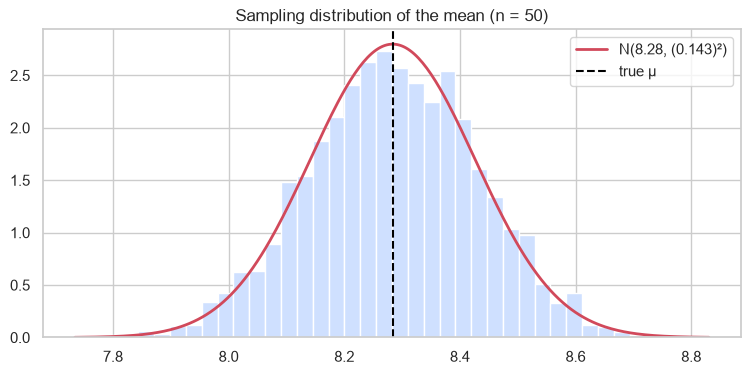

mean of sample means = 8.2844   vs   mu       = 8.2838
std  of sample means = 0.1468   vs   sigma/√n = 0.1426


In [77]:
# The CLT prediction, checked on our own CGPA data
n_ = 50
sample_means = np.array([population[COL].sample(n_, replace=True).mean() for _ in range(3000)])

plt.figure(figsize=(9, 4))
plt.hist(sample_means, bins=40, density=True, color="#cfe0ff", edgecolor="white")
xs = np.linspace(sample_means.min(), sample_means.max(), 300)
plt.plot(xs, stats.norm.pdf(xs, MU, SIGMA/np.sqrt(n_)), color=RED, lw=2,
         label=f"N({MU:.2f}, ({SIGMA/np.sqrt(n_):.3f})²)")
plt.axvline(MU, color="black", ls="--", label="true μ")
plt.title(f"Sampling distribution of the mean (n = {n_})"); plt.legend(); plt.show()

print(f"mean of sample means = {sample_means.mean():.4f}   vs   mu       = {MU:.4f}")
print(f"std  of sample means = {sample_means.std(ddof=1):.4f}   vs   sigma/√n = {SIGMA/np.sqrt(n_):.4f}")

---
# Part 7 — Hypothesis Testing & the Z-Test

### 🎞️ Slides: *The courtroom analogy* / *α, p-value, and the decision*

- $H_0$ = nothing is happening (assumed true until evidence says otherwise)
- $H_1$ = what you want to prove
- $p \le \alpha$ → **reject $H_0$** · $p > \alpha$ → **fail to reject** (never "accept")

In [78]:
crit = pd.DataFrame([
    ("Two-tailed",  0.05, f"±{stats.norm.ppf(0.975):.3f}"),
    ("One-tailed",  0.05, f"±{stats.norm.ppf(0.95):.3f}"),
    ("Two-tailed",  0.01, f"±{stats.norm.ppf(0.995):.3f}"),
], columns=["test", "alpha", "critical z"])
display(crit)

print("norm.ppf gives the critical value · norm.cdf gives the p-value")

,test,alpha,critical z
0,Two-tailed,0.05,±1.960
1,One-tailed,0.05,±1.645
2,Two-tailed,0.01,±2.576


norm.ppf gives the critical value · norm.cdf gives the p-value


### 🎞️ Slide: *Where is the rejection region?*

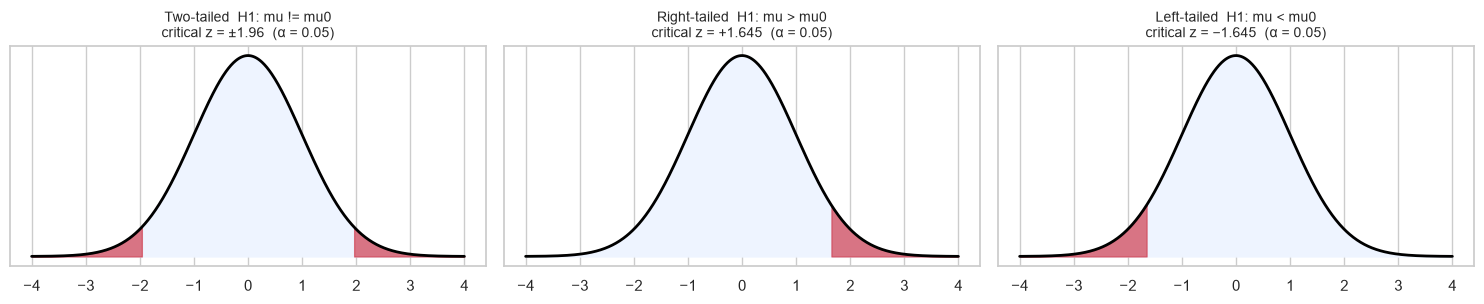

α is the TOTAL red area. Two-tailed splits it 2.5% + 2.5%, so the cut-off moves out to 1.96.


In [79]:
xs = np.linspace(-4, 4, 700)
pdf = stats.norm.pdf(xs)
setups = [("Two-tailed  H1: mu != mu0", [(-4, -1.96), (1.96, 4)], "±1.96"),
          ("Right-tailed  H1: mu > mu0", [(1.645, 4)], "+1.645"),
          ("Left-tailed  H1: mu < mu0", [(-4, -1.645)], "−1.645")]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, (title, regions, lbl) in zip(axes, setups):
    ax.plot(xs, pdf, color="black", lw=2)
    ax.fill_between(xs, pdf, color="#eef4ff")
    for a_, b_ in regions:
        m = (xs >= a_) & (xs <= b_)
        ax.fill_between(xs[m], pdf[m], color=RED, alpha=.75)
    ax.set_title(f"{title}\ncritical z = {lbl}  (α = 0.05)", fontsize=10)
    ax.set_yticks([])
plt.tight_layout(); plt.show()

print("α is the TOTAL red area. Two-tailed splits it 2.5% + 2.5%, so the cut-off moves out to 1.96.")

### 🎞️ Slide: *Type I vs Type II errors*

| | $H_0$ TRUE | $H_0$ FALSE |
|---|---|---|
| **Reject $H_0$** | ❌ Type I (α) | ✅ Correct |
| **Fail to reject** | ✅ Correct | ❌ Type II (β) |

Let's *see* the Type I rate: run 1000 tests where $H_0$ is true **by construction**.

rejected H0 in 51/1000 tests = 5.1%
expected ≈ 5% = alpha. Those are TYPE I ERRORS - false positives we knowingly accept.


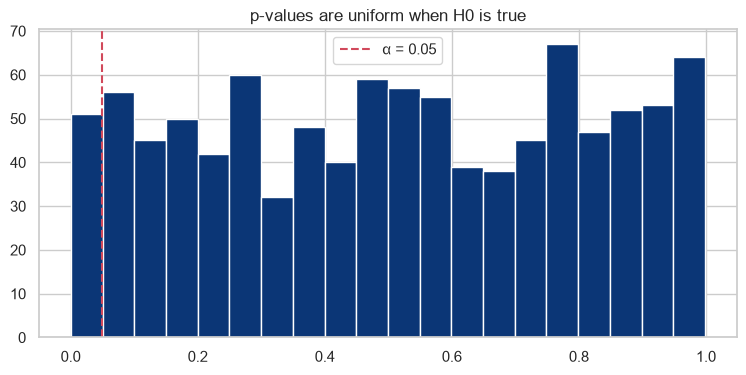

In [80]:
true_mu, true_sigma, n_, alpha = 20.0, 1.5, 36, 0.05
pvals = []
for _ in range(1000):
    smp = np.random.normal(true_mu, true_sigma, n_)          # H0 is genuinely true
    zstat = (smp.mean() - true_mu) / (true_sigma / np.sqrt(n_))
    pvals.append(2 * (1 - stats.norm.cdf(abs(zstat))))
pvals = np.array(pvals)

print(f"rejected H0 in {(pvals < alpha).sum()}/1000 tests = {(pvals < alpha).mean()*100:.1f}%")
print("expected ≈ 5% = alpha. Those are TYPE I ERRORS - false positives we knowingly accept.")

plt.hist(pvals, bins=20, color=BLUE, edgecolor="white")
plt.axvline(alpha, color=RED, ls="--", label="α = 0.05")
plt.title("p-values are uniform when H0 is true"); plt.legend(); plt.show()

### 🎞️ Slides: *When do I use a Z-test?* / *The 6-step recipe*

$$z=\frac{\bar{x}-\mu_0}{\sigma/\sqrt{n}}=\frac{\text{signal}}{\text{noise}}$$

σ known **and/or** n ≥ 30 → **Z-test**  ·  σ unknown **and** n < 30 → **t-test**

In [81]:
def z_test(sample, mu0, sigma=None, alpha=0.05, tail="two", unit=""):
    """One-sample Z-test written as the 6-step recipe from the slides."""
    x = np.asarray(sample, float)
    n = len(x)
    xbar = x.mean()
    sigma = x.std(ddof=1) if sigma is None else sigma

    # step 3 - assumptions
    assert n >= 30 or sigma is not None, "n < 30 and sigma unknown -> use a t-test"

    se = sigma / np.sqrt(n)                       # step 4
    z = (xbar - mu0) / se

    if tail == "two":                             # step 5
        p, cv, reject = 2 * (1 - stats.norm.cdf(abs(z))), stats.norm.ppf(1 - alpha/2), None
        reject = abs(z) > cv
        cv_txt, sign = f"±{cv:.3f}", "≠"
    elif tail == "right":
        p, cv = 1 - stats.norm.cdf(z), stats.norm.ppf(1 - alpha)
        reject, cv_txt, sign = z > cv, f"{cv:+.3f}", ">"
    else:
        p, cv = stats.norm.cdf(z), stats.norm.ppf(alpha)
        reject, cv_txt, sign = z < cv, f"{cv:+.3f}", "<"

    zc = stats.norm.ppf(1 - alpha/2)
    ci = (xbar - zc*se, xbar + zc*se)

    print(f"1. H0: mu = {mu0}{unit}   |   H1: mu {sign} {mu0}{unit}")
    print(f"2. alpha = {alpha}  ({tail}-tailed)   critical z = {cv_txt}")
    print(f"3. n = {n}, sigma {'known' if sigma is not None else 'estimated'} -> Z-test OK")
    print(f"4. SE = {sigma}/sqrt({n}) = {se:.4f}   ->   z = ({xbar:.4f} - {mu0}) / {se:.4f} = {z:.4f}")
    print(f"5. p-value = {p:.6f}")
    print(f"6. {'REJECT H0' if reject else 'FAIL TO REJECT H0'}"
          f"   |   {int((1-alpha)*100)}% CI = [{ci[0]:.4f}, {ci[1]:.4f}]{unit}")
    return {"z": z, "p": p, "ci": ci, "reject": reject}


print("helper ready")

helper ready


### 🎞️ Slides: *Worked example 🎯* / *The same example, drawn*

A printer is advertised at **20 pages per minute**, σ = 1.5 ppm.
A reviewer tests **n = 36** printers and measures **x̄ = 19.4 ppm**. Is it slower than advertised?

In [ ]:
mu0 = 20.0  # popultion mean
sigma_known =  1.5 # popultion standard deviation  
n_p = 36     #number of printers
xbar_p = 19.4   # sample mean

se_p = sigma_known / np.sqrt(n_p)
z_p  = (xbar_p - mu0) / se_p  #Z-Score value
print(z_p)
p_p  = stats.norm.cdf(z_p)  # pvalue        # left-tailed

p_p

-2.4000000000000057


np.float64(0.008197535924595998)

In [ ]:
print(f"SE = {sigma_known}/sqrt({n_p}) = {se_p:.4f}")
print(f"z  = ({xbar_p} - {mu0}) / {se_p} = {z_p:.4f}")
print(f"p  = Phi({z_p:.2f}) = {p_p:.6f}")
print(f"critical z (alpha=0.05, left) = {stats.norm.ppf(0.05):.4f}")


if p_p < 0.05:
    print("REJECT H0 -> the printer IS slower than 20 ppm")
else:
    print("FAIL TO REJECT H0")
    



SE = 1.5/sqrt(36) = 0.2500
z  = (19.4 - 20.0) / 0.25 = -2.4000
p  = Phi(-2.40) = 0.008198
critical z (alpha=0.05, left) = -1.6449
REJECT H0 -> the printer IS slower than 20 ppm


C:\Users\v-maheshkur\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


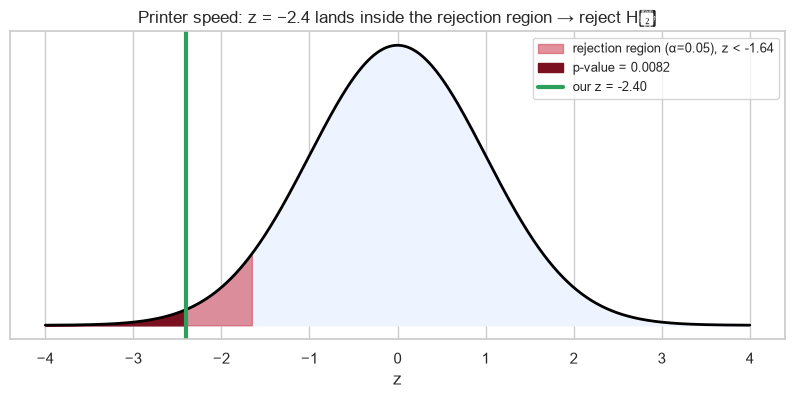

In [83]:
xs = np.linspace(-4, 4, 700)
pdf = stats.norm.pdf(xs)
cv = stats.norm.ppf(0.05)

plt.figure(figsize=(10, 4))
plt.plot(xs, pdf, color="black", lw=2)
plt.fill_between(xs, pdf, color="#eef4ff")
plt.fill_between(xs[xs <= cv],  pdf[xs <= cv],  color=RED, alpha=.6,
                 label=f"rejection region (α=0.05), z < {cv:.2f}")
plt.fill_between(xs[xs <= z_p], pdf[xs <= z_p], color="#7a1020",
                 label=f"p-value = {p_p:.4f}")
plt.axvline(z_p, color=GREEN, lw=3, label=f"our z = {z_p:.2f}")
plt.title("Printer speed: z = −2.4 lands inside the rejection region → reject H₀")
plt.yticks([]); plt.xlabel("z"); plt.legend(fontsize=9); plt.show()

### 🎞️ Slides: *Confidence Interval* / *What "95% confidence" really means*

$$CI = \bar{x} \pm z_{\alpha/2}\cdot\frac{\sigma}{\sqrt{n}}$$

In [84]:
ci_p = (xbar_p - 1.96*se_p, xbar_p + 1.96*se_p)
print(f"95% CI = [{ci_p[0]:.4f}, {ci_p[1]:.4f}] ppm")
print(f"20 ppm is {'INSIDE' if ci_p[0] <= 20 <= ci_p[1] else 'OUTSIDE'} the interval -> same conclusion as the test")
print("Bonus: the CI also tells us the real speed is roughly 18.9 to 19.9 ppm.")

95% CI = [18.9100, 19.8900] ppm
20 ppm is OUTSIDE the interval -> same conclusion as the test
Bonus: the CI also tells us the real speed is roughly 18.9 to 19.9 ppm.


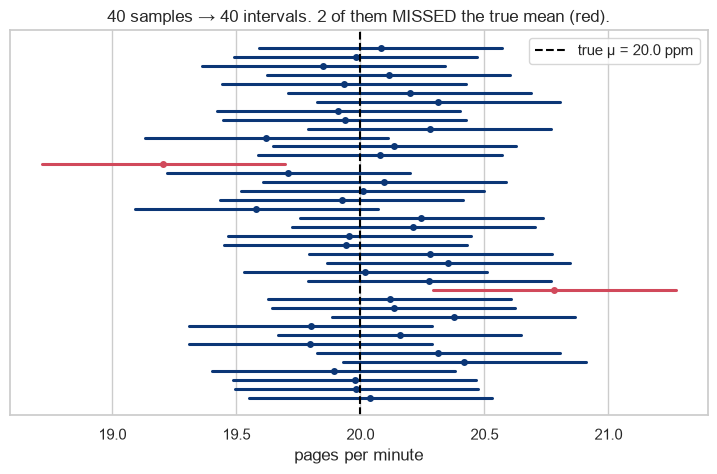

The PROCEDURE is 95% reliable - not any single interval you happen to compute.


In [85]:
# 40 samples -> 40 different intervals. About 5% miss the true mean.
plt.figure(figsize=(9, 5))
missed = 0
for i in range(40):
    xb = np.random.normal(mu0, sigma_known / np.sqrt(n_p))
    lo_, hi_ = xb - 1.96*se_p, xb + 1.96*se_p
    hit = lo_ <= mu0 <= hi_
    missed += not hit
    plt.plot([lo_, hi_], [i, i], color=BLUE if hit else RED, lw=2.2)
    plt.plot(xb, i, "o", color=BLUE if hit else RED, ms=4)
plt.axvline(mu0, color="black", ls="--", label=f"true μ = {mu0} ppm")
plt.yticks([]); plt.xlabel("pages per minute"); plt.legend()
plt.title(f"40 samples → 40 intervals. {missed} of them MISSED the true mean (red).")
plt.show()

print("The PROCEDURE is 95% reliable - not any single interval you happen to compute.")

### 🎞️ Slide: *Statistical ≠ Practical significance*

In [86]:
effect, sigma_e = 0.02, 0.8          # a meaningless 0.02 CGPA difference
rows = []
for n_ in [30, 100, 1_000, 10_000, 1_000_000]:
    z_ = effect / (sigma_e / np.sqrt(n_))
    p_ = 2 * (1 - stats.norm.cdf(abs(z_)))
    rows.append({"n": f"{n_:,}", "z": round(z_, 3), "p-value": f"{p_:.6f}",
                 "significant?": "YES" if p_ < 0.05 else "no",
                 "Cohen's d": round(effect / sigma_e, 4)})
display(pd.DataFrame(rows))

print("The effect size never changes (d = 0.025, negligible) - only the p-value does.")
print("Always report an effect size next to the p-value.")

,n,z,p-value,significant?,Cohen's d
0,30,0.137,0.891086,no,0.025
1,100,0.250,0.802587,no,0.025
2,"1,000",0.791,0.429195,no,0.025
3,"10,000",2.500,0.012419,YES,0.025
4,"1,000,000",25.000,0.000000,YES,0.025


The effect size never changes (d = 0.025, negligible) - only the p-value does.
Always report an effect size next to the p-value.


### 🎞️ Slide: *Cheat sheet*

In [87]:
c = COL
print(f"mean            {df[c].mean():.4f}")
print(f"median          {df[c].median():.4f}")
print(f"mode            {df[c].mode()[0]:.4f}")
print(f"variance        {df[c].var():.4f}")
print(f"std dev         {df[c].std():.4f}")
print(f"IQR             {df[c].quantile(.75) - df[c].quantile(.25):.4f}")
print(f"skewness        {df[c].skew():.4f}")
print(f"z-score of row0 {stats.zscore(df[c])[0]:.4f}")
print(f"norm.cdf(1.96)  {stats.norm.cdf(1.96):.4f}")
print(f"norm.ppf(0.975) {stats.norm.ppf(0.975):.4f}")
print(f"random sample   {len(df.sample(n=100, random_state=42))} rows")
print(f"stratified      {len(df.groupby('branch', group_keys=False).sample(frac=0.1, random_state=42))} rows")

mean            8.2838
median          8.3200
mode            10.0000
variance        1.0169
std dev         1.0084
IQR             1.4100
skewness        -0.2876
z-score of row0 0.4525
norm.cdf(1.96)  0.9750
norm.ppf(0.975) 1.9600
random sample   100 rows
stratified      499 rows


---
## 🧪 Your turn — one exercise per Part

1. **Central tendency** — mean, median and mode of `study_hours_per_day`. Which one describes a typical student best, and why?
2. **Dispersion** — which of the six overview columns has the widest IQR? Which has the most 1.5×IQR outliers?
3. **Distributions** — is `attendance_percentage` symmetric or skewed? Check its skewness and whether it obeys the 68–95–99.7 rule.
4. **Probability** — compute $P(\text{placed-ready} \mid \text{branch})$ using `internships_completed > 0`. Which branch has the highest?
5. **Z-scores** — write `percentile(marks)` for an exam with μ = 65, σ = 12. What mark puts a student in the top 10%? (hint: `norm.ppf`)
6. **Sampling** — draw a 10% stratified sample by `city_tier` and compare its mean CGPA with the population.
7. **Z-test** — a coaching centre claims its students average **7.5 CGPA**. Test that claim against a sample of 100 students from our data with `z_test(...)`. State H₀, H₁, the p-value, the CI and your decision **in plain English**.

In [88]:
# your answers here